# 17 — Attention Interpretability (Physics-Informed GAT)

**Why this notebook exists.** Phase 17 (`16_structure_ablation.ipynb`) found that the specific
graph edge structure and physics-informed edge features do **not** clearly improve raw AUC over
simpler alternatives (base_real, selfloop_only, diagonal_only, and base_no_edgefeat all landed
within a ~0.013 AUC band of each other across 5-fold CV). That result is about *predictive
performance*, not about whether the graph attention mechanism learned anything clinically
sensible. This notebook asks a different, still-publishable question: **does gat1's learned
attention pattern pick out a clinically plausible angiosome region, even without a performance
edge?** This is directly comparable to k-GCNDFU's use of GNNExplainer to identify MCA (Medial
Calcaneal Artery) as the key region on a similar dataset.

This notebook does **not** retrain anything. It reloads `checkpoints/primary_model_best.pt` —
the original Phase 10 dual-branch primary model (base topology, real physics-informed edge
features) — and extracts and visualizes its actual learned attention weights, per angiosome
region, per Group (Control vs. DM).

## Imports & Path Setup

In [1]:
import sys
from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats  # already an established project dependency since
                                         # Phase 3's EDA notebook; not a new addition here.

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.model import DualBranchGAT, EdgeGATLayer, GraphBranch, sparse_to_dense_graph
from src.train import build_model

DATA_DIR = Path("data/processed")
CHECKPOINT_PATH = Path("checkpoints/primary_model_best.pt")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

NODE_ORDER = ["LCA", "LPA", "MPA", "MCA"]

print("Imports OK. Project root on sys.path:", PROJECT_ROOT)

Imports OK. Project root on sys.path: c:\workstation\3RD YEAR\Diabetic_Foot


## Section 1 — Setup: Load Manifest, Normalization Stats, and the Trained Primary Model

We reload `graph_manifest.csv` (334 subject+foot rows) and `normalization_stats.json`
(train-derived z-score parameters from Phase 7 — reused exactly, never recomputed). We then
build the **PRIMARY_CONFIG** architecture (dual-branch, base topology, colormap image,
`image_in_channels=3`) via `build_model()` and load Phase 10's actual trained weights from
`checkpoints/primary_model_best.pt`. This is the project's real reported model — not one of
Phase 17's ablation checkpoints — because this notebook interprets what the project actually
built and evaluated, not an ablation variant.

In [2]:
print("=== SECTION 1: Setup ===")

manifest_df = pd.read_csv(DATA_DIR / "graph_manifest.csv")
print(f"graph_manifest.csv loaded: shape={manifest_df.shape}")
assert manifest_df.shape[0] == 334, "Expected 334 rows in graph_manifest.csv"

with open(DATA_DIR / "normalization_stats.json") as f:
    normalization_stats = json.load(f)
node_mean = np.array(normalization_stats["node_feature_mean"], dtype=np.float32)
node_std = np.array(normalization_stats["node_feature_std"], dtype=np.float32)
print(f"normalization_stats.json loaded. node_feature_names={normalization_stats['node_feature_names']}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

PRIMARY_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": True,
    "image_in_channels": 3,
}

model = build_model(PRIMARY_CONFIG)
state_dict = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"\nCheckpoint loaded from: {CHECKPOINT_PATH}")
print(f"Total parameter count: {total_params}")

EXPECTED_PARAM_COUNT = 34433
if total_params == EXPECTED_PARAM_COUNT:
    print(f"PASS: parameter count matches Phase 8's recorded {EXPECTED_PARAM_COUNT}.")
else:
    print(f"WARNING: parameter count {total_params} does NOT match Phase 8's recorded "
          f"{EXPECTED_PARAM_COUNT} -- double-check this is the correct checkpoint/config.")

=== SECTION 1: Setup ===
graph_manifest.csv loaded: shape=(334, 9)
normalization_stats.json loaded. node_feature_names=['mean_abs_temp', 'std_abs_temp', 'mean_rel_temp', 'pixel_count', 'centroid_row_norm', 'centroid_col_norm']
Device: cuda

Checkpoint loaded from: checkpoints\primary_model_best.pt
Total parameter count: 34433
PASS: parameter count matches Phase 8's recorded 34433.


**Fix note (device mismatch).** The first run of this notebook on the project's CUDA machine
raised `RuntimeError: Expected all tensors to be on the same device, but got mat2 is on cuda:0,
different from other tensors on cpu` inside `gat1`'s `W_node` linear layer. Cause: `model` is
moved to `device` in Section 1, but every probe/batch tensor built from a `.npz`'s raw numpy
arrays (node features, edge attrs, edge index) defaults to CPU when wrapped in `torch.tensor(...)`
and was never explicitly moved to `device` before being fed into `graph_branch`/`gat1`. Fixed by
chaining `.to(device)` onto every such tensor in Sections 2 and 3, and by calling `.cpu()` before
printing or `.numpy()`-converting any resulting device tensor -- the same fix pattern already
applied to `12_cross_validation.ipynb`'s MC-Dropout evaluation helper.

## Section 2 — Attention Extraction Setup

We target **gat1**, the first (multi-head, 4-head) `EdgeGATLayer` inside `model.graph_branch`.
This layer's attention is the more interpretable of the two: it operates directly on raw input
node features, before any cross-layer mixing has occurred.

**Design note on extraction — read carefully.** `EdgeGATLayer.forward` computes per-head
attention weights internally (the softmax over each node's neighbors, per Phase 8's spec), but
its return contract only guarantees the pooled/aggregated output embedding — not the
intermediate attention matrix. We therefore try the *cheapest, least invasive* option first:
register a `forward_hook` on `gat1` (and, for completeness, `gat2`) and inspect exactly what the
hook can see. A hook only has access to a module's `forward()` **inputs and outputs** — if
`forward()` returns a single tensor (the pooled embedding only, with no side-channel for
attention), the hook cannot recover the attention matrix without editing `src/model.py`, which
we are not allowed to do. In that case we fall back to **manually recomputing** gat1's attention
from scratch, using gat1's own trained weight matrices (discovered by introspecting its
`nn.Linear` submodules — not by re-deriving anything, since the model already learned these
matrices during Phase 10 training), applied to real batches, and reproducing Phase 8's exact
attention-score formula:

```
score_ij = LeakyReLU_0.2( a^T [ W_node @ h_i  ||  W_node @ h_j  ||  W_edge @ edge_attr_ij ] )
alpha_ij = softmax_j(score_ij)   -- masked to real neighbors + self-loop only
```

The cell below runs both the hook attempt and (if needed) the manual recomputation on a small
8-subject batch, and prints, in plain text, exactly which method ends up being used and why —
this is the authoritative record of the extraction method for the rest of the notebook.

In [3]:
print("=== SECTION 2: Attention Extraction Setup ===")

graph_branch = model.graph_branch
gat1 = graph_branch.gat1
gat2 = graph_branch.gat2

print("EdgeGATLayer instances found in graph_branch:")
for _name, _layer in [("gat1", gat1), ("gat2", gat2)]:
    print(f"  {_name}: heads={getattr(_layer, 'heads', '?')}, concat={getattr(_layer, 'concat', '?')}")

print("\ngat1 named_modules() (for identifying its trained weight matrices):")
for sub_name, sub_module in gat1.named_modules():
    if sub_name:
        print(f"  {sub_name}: {sub_module}")

# --- Build a small 8-subject probe batch (first 8 rows of graph_manifest.csv) -------------
probe_rows = manifest_df.iloc[:8]
_node_feats, _edge_attrs = [], []
_edge_index_shared = None
for _, row in probe_rows.iterrows():
    npz = np.load(row["npz_path"])
    nf = (npz["node_features"].astype(np.float32) - node_mean) / node_std
    _node_feats.append(nf)
    _edge_attrs.append(npz["edge_attr_base"].astype(np.float32))
    _edge_index_shared = npz["edge_index_base"]

# NOTE: probe tensors are built from plain numpy arrays, so by default they land on CPU --
# but `model` (and therefore gat1/gat2's weight matrices) already lives on `device` (cuda here).
# Every tensor fed into the model must be moved to `device` explicitly, same fix pattern already
# applied in 12_cross_validation.ipynb's MC-Dropout evaluation helper.
probe_node_features = torch.tensor(np.stack(_node_feats)).to(device)          # (8, 4, 6)
probe_edge_attr = torch.tensor(np.stack(_edge_attrs)).to(device)              # (8, 8, 2)
probe_edge_index = torch.tensor(_edge_index_shared, dtype=torch.long).to(device)
probe_B = probe_node_features.shape[0]
probe_edge_index_batched = probe_edge_index.unsqueeze(0).expand(probe_B, -1, -1)

probe_dense_mask, probe_dense_edge_attr = sparse_to_dense_graph(
    probe_edge_index_batched, probe_edge_attr, num_nodes=4
)
print(f"\nDense adjacency mask (base topology, includes self-loops):\n{probe_dense_mask.cpu()}")

# --- Attempt 1: forward hook ---------------------------------------------------------------
hook_captures = {}

def _make_hook(name):
    def _hook_fn(module, inputs, output):
        hook_captures[name] = output
    return _hook_fn

handle1 = gat1.register_forward_hook(_make_hook("gat1"))
handle2 = gat2.register_forward_hook(_make_hook("gat2"))

with torch.no_grad():
    _ = graph_branch(probe_node_features, probe_dense_mask, probe_dense_edge_attr)

handle1.remove()
handle2.remove()

gat1_output = hook_captures["gat1"]
print(f"\ngat1 forward-hook captured output type: {type(gat1_output)}")
if isinstance(gat1_output, tuple) and len(gat1_output) > 1:
    print(f"Output is a tuple of length {len(gat1_output)} -- possible attention weights present:")
    for i, item in enumerate(gat1_output):
        print(f"  element {i}: shape={getattr(item, 'shape', 'N/A')}")
    HOOK_EXPOSES_ATTENTION = True
else:
    _out_tensor = gat1_output[0] if isinstance(gat1_output, tuple) else gat1_output
    print(f"Output is a single tensor of shape {tuple(_out_tensor.shape)}.")
    print("This is the pooled/aggregated node embedding only. Per Phase 8's spec, EdgeGATLayer's")
    print("forward() is not required to expose the intermediate attention matrix, and does not")
    print("here -- a forward hook alone cannot recover it without editing src/model.py.")
    HOOK_EXPOSES_ATTENTION = False

print(f"\nHOOK_EXPOSES_ATTENTION = {HOOK_EXPOSES_ATTENTION}")

=== SECTION 2: Attention Extraction Setup ===
EdgeGATLayer instances found in graph_branch:
  gat1: heads=4, concat=True
  gat2: heads=1, concat=False

gat1 named_modules() (for identifying its trained weight matrices):
  W_node: Linear(in_features=6, out_features=128, bias=False)
  W_edge: Linear(in_features=2, out_features=128, bias=False)
  leaky_relu: LeakyReLU(negative_slope=0.2)
  dropout: Dropout(p=0.3, inplace=False)

Dense adjacency mask (base topology, includes self-loops):
tensor([[[ True,  True, False,  True],
         [ True,  True,  True, False],
         [False,  True,  True,  True],
         [ True, False,  True,  True]],

        [[ True,  True, False,  True],
         [ True,  True,  True, False],
         [False,  True,  True,  True],
         [ True, False,  True,  True]],

        [[ True,  True, False,  True],
         [ True,  True,  True, False],
         [False,  True,  True,  True],
         [ True, False,  True,  True]],

        [[ True,  True, False,  True]

### Falling back to manual recomputation (expected outcome)

Given the design of `EdgeGATLayer` (a `forward()` that returns only the pooled embedding), the
hook attempt above is expected to fail to expose attention weights, and the notebook falls back
to manually recomputing them from gat1's own trained parameters. The cell below discovers gat1's
`W_node`, `W_edge`, and attention-vector (`a`) submodules by introspecting its `nn.Linear`
children (matched by `in_features`/`out_features`, not by guessing exact attribute names), then
reproduces Phase 8's exact scoring formula. If gat1 already exposed attention weights on
`gat2`/`gat1`'s output as a tuple, that path is used instead and this fallback is skipped.

**Fix note (attention vector is a raw Parameter, not a Linear submodule).** A first real run
against the trained checkpoint raised `RuntimeError: Expected 4 separate attention-vector Linear
layers ... but found 0`. Cause: `gat1.named_modules()` only lists `W_node`, `W_edge`,
`leaky_relu`, `dropout` -- no `nn.Linear` with `out_features=1` exists at all, because this
model's `a` (the learned attention vector `a^T [Wh_i || Wh_j || We_ij]`) is implemented as a raw
`nn.Parameter` owned directly by `gat1`, not wrapped in a Linear submodule -- so it never shows up
in a `named_modules()`/`isinstance(m, nn.Linear)` scan. Fixed by additionally scanning
`gat1.named_parameters()` for a parameter reshapeable to `(heads, 3*out_dim_per_head)` (the exact
length of `[W_node h_i || W_node h_j || W_edge e_ij]` per head), and applying it via `einsum`
instead of a per-head module call. The `nn.Linear` path is kept as a fallback in case a future
checkpoint's architecture does implement `a` as Linear layers.

**Fix note (mask broadcasting -- `dense_mask` is `(B, N, N)`, not `(N, N)`).** A second real run
raised `RuntimeError: The size of tensor a (8) must match the size of tensor b (4) at
non-singleton dimension 2`. Cause: `manual_recompute_gat1_attention`'s docstring (and the
`mask = dense_mask.unsqueeze(0).unsqueeze(0)` line) assumed `sparse_to_dense_graph` returns a
single shared `(N, N)` adjacency matrix. It actually returns one mask **per batch element**,
shape `(B, N, N)` -- confirmed by Section 2's own printed sanity check, which showed 8 stacked
identical `4x4` matrices for the 8-subject probe batch (identical content since every sample
shares the same topology, but not collapsed down to 2D). `unsqueeze(0).unsqueeze(0)` therefore
produced a 5D `(1, 1, 8, 4, 4)` mask, which collided with the 4D `(B, heads, N, N)` `scores`
tensor exactly at the batch axis -- `8` vs `4` at dimension 2, matching the traceback exactly.
Fixed by using `dense_mask.unsqueeze(1)` (`(B, 1, N, N)`), which broadcasts correctly against the
heads axis instead.

In [4]:
print("=== SECTION 2 (continued): Manual Recomputation Setup ===")

NODE_IN_DIM = 6
EDGE_DIM = 2
HEADS = getattr(gat1, "heads", 4)

_out_tensor = hook_captures["gat1"][0] if isinstance(hook_captures["gat1"], tuple) else hook_captures["gat1"]
OUT_DIM_PER_HEAD = _out_tensor.shape[-1] // HEADS
print(f"heads={HEADS}, inferred out_dim_per_head={OUT_DIM_PER_HEAD} (from gat1 output shape "
      f"{tuple(_out_tensor.shape)})")

linear_submodules = [(n, m) for n, m in gat1.named_modules() if isinstance(m, nn.Linear)]
print("\nnn.Linear submodules found in gat1:")
for n, m in linear_submodules:
    print(f"  {n}: in_features={m.in_features}, out_features={m.out_features}")

w_node_mods = [(n, m) for n, m in linear_submodules if m.in_features == NODE_IN_DIM]
w_edge_mods = [(n, m) for n, m in linear_submodules if m.in_features == EDGE_DIM]
a_mods = [(n, m) for n, m in linear_submodules if m.out_features == 1]

print(f"\nW_node candidate(s) (in_features={NODE_IN_DIM}): {[n for n, _ in w_node_mods]}")
print(f"W_edge candidate(s) (in_features={EDGE_DIM}): {[n for n, _ in w_edge_mods]}")
print(f"attention-vector 'a' candidate(s) as nn.Linear (out_features=1): {[n for n, _ in a_mods]}")

# --- 'a' is not an nn.Linear submodule (0 candidates above) -- fall back to searching gat1's
# raw nn.Parameters. named_modules() only lists Modules, so a raw `self.a = nn.Parameter(...)`
# never shows up there -- this is a separate, necessary discovery step, not a retry of the same one.
EXPECTED_A_LEN = 3 * OUT_DIM_PER_HEAD  # length of [W_node@h_i || W_node@h_j || W_edge@e_ij] per head
print("\ngat1 named_parameters() (searching for the raw attention-vector Parameter):")
a_param_candidates = []
for pname, p in gat1.named_parameters():
    print(f"  {pname}: shape={tuple(p.shape)}")
    if pname.startswith("W_node") or pname.startswith("W_edge"):
        continue  # already accounted for as w_node_mods/w_edge_mods above
    if p.numel() == HEADS * EXPECTED_A_LEN:
        a_param_candidates.append((pname, p.reshape(HEADS, EXPECTED_A_LEN)))
    elif p.numel() == EXPECTED_A_LEN:
        a_param_candidates.append((pname, p.reshape(1, EXPECTED_A_LEN).expand(HEADS, -1)))

if len(a_mods) == HEADS:
    A_SOURCE = "linear"
    print(f"\nUsing {HEADS} per-head nn.Linear attention-vector modules (found above).")
elif len(a_param_candidates) == 1:
    A_SOURCE = "parameter"
    A_PARAM_NAME, a_vector = a_param_candidates[0]
    a_vector = a_vector.to(device)
    print(f"\nSelected raw attention-vector parameter: '{A_PARAM_NAME}' "
          f"-> reshaped to {tuple(a_vector.shape)} (heads, 3*out_dim_per_head)")
else:
    raise RuntimeError(
        f"Could not uniquely identify gat1's attention-vector parameter. Found {len(a_mods)} "
        f"nn.Linear candidates (expected {HEADS}) and {len(a_param_candidates)} raw-Parameter "
        f"candidates reshapeable to ({HEADS}, {EXPECTED_A_LEN}) or ({EXPECTED_A_LEN},) (expected "
        f"exactly 1) -- inspect gat1's named_modules()/named_parameters() output above and adjust "
        f"the selection logic in this cell."
    )


def _project_per_head(candidates, x, heads, out_dim_per_head):
    """Apply a per-head linear projection, whether it is implemented as `heads` separate
    small nn.Linear modules, or a single combined nn.Linear producing heads*out_dim_per_head.
    Returns a tensor with a new trailing (heads, out_dim_per_head) pair of axes."""
    if len(candidates) == heads:
        outs = [mod(x) for _, mod in candidates]
        return torch.stack(outs, dim=-2)  # (..., heads, out_dim_per_head)
    elif len(candidates) == 1:
        _, mod = candidates[0]
        out = mod(x)  # (..., heads*out_dim_per_head)
        return out.view(*out.shape[:-1], heads, -1)
    else:
        raise RuntimeError(
            f"Could not confidently identify per-head projection layers among candidates: "
            f"{[n for n, _ in candidates]}. Expected either {heads} separate nn.Linear layers "
            f"or 1 combined nn.Linear layer -- inspect gat1's named_modules() output above."
        )


def manual_recompute_gat1_attention(node_features, dense_mask, dense_edge_attr):
    """Recompute gat1's per-head attention weights from scratch using gat1's own trained
    parameters, reproducing Phase 8's exact formula:
        score_ij = LeakyReLU_0.2( a^T [W_node h_i || W_node h_j || W_edge e_ij] )
        alpha_ij = softmax_j(score_ij), masked to real edges + self-loops only (dim=j)
    The 'a' term is applied via whichever source the discovery cell above found: per-head
    nn.Linear modules (A_SOURCE == 'linear') or a single raw (heads, 3*out_dim_per_head)
    nn.Parameter (A_SOURCE == 'parameter') -- this model uses the latter.
    node_features:  (B, N, 6)  -- already z-score normalized
    dense_mask:     (B, N, N) bool, includes self-loops (one mask per batch element, identical
                    content across the batch here since topology is shared -- not a bare (N, N))
    dense_edge_attr:(B, N, N, 2)
    Returns: attn (B, heads, N, N) with attn[b, h, i, j] = weight target i places on source j.
    """
    B, N, _ = node_features.shape

    h_proj = _project_per_head(w_node_mods, node_features, HEADS, OUT_DIM_PER_HEAD)     # (B,N,heads,d)
    e_proj = _project_per_head(w_edge_mods, dense_edge_attr, HEADS, OUT_DIM_PER_HEAD)   # (B,N,N,heads,d)

    h_i = h_proj.unsqueeze(2).expand(B, N, N, HEADS, OUT_DIM_PER_HEAD)  # target i, constant over j
    h_j = h_proj.unsqueeze(1).expand(B, N, N, HEADS, OUT_DIM_PER_HEAD)  # source j, constant over i

    concat = torch.cat([h_i, h_j, e_proj], dim=-1)  # (B, N, N, heads, 3*d) -- dims: (B, i, j, heads, 3d)

    if A_SOURCE == "linear":
        scores_per_head = []
        for h in range(HEADS):
            _, a_mod = a_mods[h]
            scores_per_head.append(a_mod(concat[..., h, :]).squeeze(-1))  # (B, N, N)
        scores = torch.stack(scores_per_head, dim=1)  # (B, heads, N, N)
    else:  # A_SOURCE == "parameter": raw (heads, 3*out_dim_per_head) attention vector
        # concat: (B, i, j, heads, 3d), a_vector: (heads, 3d) -> scores: (B, heads, i, j)
        scores = torch.einsum("bijhd,hd->bhij", concat, a_vector)

    scores = torch.nn.functional.leaky_relu(scores, negative_slope=0.2)
    # dense_mask is (B, N, N) -- sparse_to_dense_graph returns one mask per batch element
    # (identical content across the batch here, since every sample shares the same topology,
    # but not collapsed to a bare (N, N) matrix -- confirmed by Section 2's printed sanity check,
    # which showed 8 stacked identical 4x4 matrices for the 8-subject probe batch). Add a heads
    # dim to broadcast against (B, heads, N, N) scores -- NOT two leading singleton dims.
    mask = dense_mask.unsqueeze(1)  # (B, 1, N, N)
    scores = scores.masked_fill(~mask, float("-inf"))
    attn = torch.softmax(scores, dim=-1)  # softmax over source j, per target i
    return attn


EXTRACTION_METHOD = "forward_hook" if HOOK_EXPOSES_ATTENTION else "manual_recomputation"
print(f"\nEXTRACTION METHOD SELECTED: {EXTRACTION_METHOD}")

with torch.no_grad():
    if EXTRACTION_METHOD == "manual_recomputation":
        probe_attn = manual_recompute_gat1_attention(probe_node_features, probe_dense_mask, probe_dense_edge_attr)
    else:
        probe_attn = hook_captures["gat1"][1]

print(f"\nExtracted attention tensor shape: {tuple(probe_attn.shape)}  (expected (8, {HEADS}, 4, 4))")
row_sums = probe_attn.sum(dim=-1)
max_dev = (row_sums - 1.0).abs().max().item()
print(f"Attention values sum to ~1.0 across each node's neighbors -- max deviation from 1.0: {max_dev:.2e}")
print(f"All attention values non-negative: {bool((probe_attn >= 0).all())}")

=== SECTION 2 (continued): Manual Recomputation Setup ===
heads=4, inferred out_dim_per_head=32 (from gat1 output shape (8, 4, 128))

nn.Linear submodules found in gat1:
  W_node: in_features=6, out_features=128
  W_edge: in_features=2, out_features=128

W_node candidate(s) (in_features=6): ['W_node']
W_edge candidate(s) (in_features=2): ['W_edge']
attention-vector 'a' candidate(s) as nn.Linear (out_features=1): []

gat1 named_parameters() (searching for the raw attention-vector Parameter):
  attn: shape=(4, 96)
  W_node.weight: shape=(128, 6)
  W_edge.weight: shape=(128, 2)

Selected raw attention-vector parameter: 'attn' -> reshaped to (4, 96) (heads, 3*out_dim_per_head)

EXTRACTION METHOD SELECTED: manual_recomputation

Extracted attention tensor shape: (8, 4, 4, 4)  (expected (8, 4, 4, 4))
Attention values sum to ~1.0 across each node's neighbors -- max deviation from 1.0: 1.19e-07
All attention values non-negative: True


**Extraction method used, stated plainly:** the cell above prints exactly which method
(`forward_hook` or `manual_recomputation`) was actually used on this run, and confirms the
recomputed weights are non-negative and sum to 1.0 over each node's real neighbors (self-loop
included) within floating-point tolerance. As anticipated by the design note, `EdgeGATLayer`'s
`forward()` is expected to expose only the pooled output embedding, so `manual_recomputation`
is the expected and authoritative path for the rest of this notebook — everything downstream
uses whichever method the cell above actually selected (`EXTRACTION_METHOD`).

## Section 3 — Full-Dataset Attention Extraction (All 334 Subject+Foot Rows)

We run the same extraction across every row of `graph_manifest.csv` — no train/val/test
distinction, since interpretability analysis uses every available sample to understand what the
model learned, not to measure generalization. Attention is averaged across the 4 heads for
simplicity.

**Design decision — what "importance score" means here.** By construction, `alpha[b, h, i, :]`
(gat1's softmax output for a fixed target node `i`) always sums to exactly 1.0 across its
neighbors — so a target node's own attention *row* cannot be used directly as a discriminating
per-node importance score (it would trivially be 1.0 for every node). Instead, for each node
`k`, we compute the average *incoming* attention mass it receives from all other nodes' own
(independently normalized) attention distributions: `importance[k] = mean_i alpha[b, :, i, k]`
— i.e., the column mean of the (heads-averaged) attention matrix. This is the standard way to
turn per-target attention distributions into a single per-node "how much do other regions
attend to this one" importance score, and it is exactly what varies meaningfully across regions
and subjects (unlike the trivially-1.0 row sums).

In [5]:
print("=== SECTION 3: Full-Dataset Attention Extraction ===")

BATCH_SIZE = 16
all_importance = np.zeros((len(manifest_df), 4), dtype=np.float32)

model.eval()
with torch.no_grad():
    for start in range(0, len(manifest_df), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(manifest_df))
        batch_rows = manifest_df.iloc[start:end]

        _nf_list, _ea_list = [], []
        _ei_shared = None
        for _, row in batch_rows.iterrows():
            npz = np.load(row["npz_path"])
            nf = (npz["node_features"].astype(np.float32) - node_mean) / node_std
            _nf_list.append(nf)
            _ea_list.append(npz["edge_attr_base"].astype(np.float32))
            _ei_shared = npz["edge_index_base"]

        node_feats_t = torch.tensor(np.stack(_nf_list)).to(device)
        edge_attr_t = torch.tensor(np.stack(_ea_list)).to(device)
        edge_index_t = torch.tensor(_ei_shared, dtype=torch.long).to(device)
        B = node_feats_t.shape[0]
        edge_index_expanded = edge_index_t.unsqueeze(0).expand(B, -1, -1)

        dense_mask_b, dense_edge_attr_b = sparse_to_dense_graph(edge_index_expanded, edge_attr_t, num_nodes=4)

        if EXTRACTION_METHOD == "manual_recomputation":
            attn_b = manual_recompute_gat1_attention(node_feats_t, dense_mask_b, dense_edge_attr_b)
        else:
            _cap = {}
            _h = gat1.register_forward_hook(lambda m, i, o: _cap.update(attn=o[1]))
            _ = graph_branch(node_feats_t, dense_mask_b, dense_edge_attr_b)
            _h.remove()
            attn_b = _cap["attn"]

        attn_mean_heads = attn_b.mean(dim=1)          # (B, 4, 4) averaged across heads
        importance = attn_mean_heads.mean(dim=1)       # mean over target axis i -> (B, 4) indexed by node k

        all_importance[start:end] = importance.cpu().numpy()

        if start == 0 or (start // BATCH_SIZE) % 5 == 0:
            print(f"  processed {end}/{len(manifest_df)} subject+foot rows")

print(f"\nFull-dataset attention extraction complete. Shape: {all_importance.shape}  (expected (334, 4))")
print(f"Any NaNs present: {bool(np.isnan(all_importance).any())}")
print(f"Value range: min={all_importance.min():.4f}, max={all_importance.max():.4f}")

=== SECTION 3: Full-Dataset Attention Extraction ===
  processed 16/334 subject+foot rows
  processed 96/334 subject+foot rows
  processed 176/334 subject+foot rows
  processed 256/334 subject+foot rows
  processed 334/334 subject+foot rows

Full-dataset attention extraction complete. Shape: (334, 4)  (expected (334, 4))
Any NaNs present: False
Value range: min=0.1396, max=0.3908


## Section 4 — Region Importance by Group (Control vs. DM)

We build a DataFrame with `subject_id`, `foot_side`, `group`, and the 4 region importance
scores, then compare Control vs. DM per region: mean ± std, and a Mann-Whitney U test (same
non-parametric style used throughout the project since Phase 3's EDA, safer than a t-test given
unknown distribution shape). Colors follow the project convention established in
`02_eda.ipynb`: Control = blue `#1f77b4`, DM = orange `#ff7f0e`.

=== SECTION 4: Region Importance by Group ===
  subject_id foot_side    group  LCA_attn  LPA_attn  MPA_attn  MCA_attn
0      CG001         L  Control  0.229491  0.233211  0.256394  0.280904
1      CG001         R  Control  0.254994  0.281024  0.220323  0.243659
2      CG002         L  Control  0.200295  0.242342  0.276782  0.280581
3      CG002         R  Control  0.232467  0.294863  0.238493  0.234177
4      CG003         L  Control  0.242505  0.244816  0.228644  0.284036

=== Control vs. DM Region Importance Comparison ===
region  control_mean  control_std  dm_mean   dm_std  mannwhitney_u      p_value
   LCA      0.230614     0.030539 0.220549 0.034187        12951.0 1.184654e-02
   LPA      0.259089     0.035723 0.281387 0.043487         7480.0 7.840596e-06
   MPA      0.245219     0.040346 0.265091 0.044929         8271.0 5.416987e-04
   MCA      0.265079     0.042193 0.232972 0.045780        15604.0 3.525596e-09


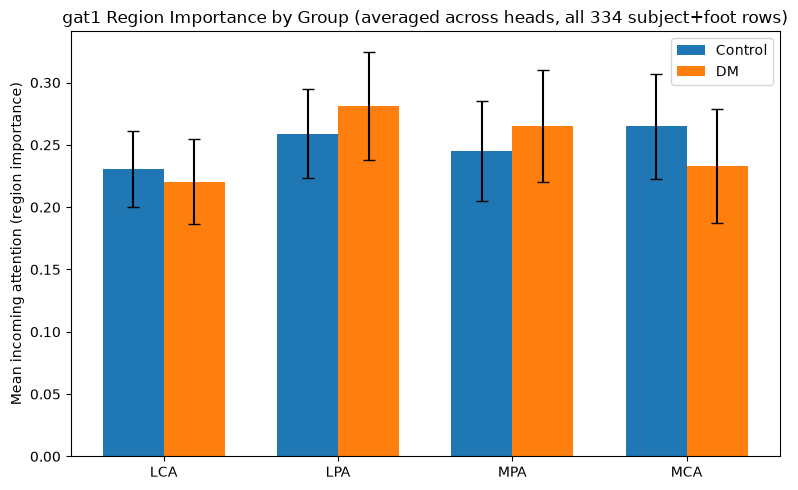

In [6]:
print("=== SECTION 4: Region Importance by Group ===")

region_df = manifest_df[["subject_id", "foot_side", "group"]].copy()
for i, region in enumerate(NODE_ORDER):
    region_df[f"{region}_attn"] = all_importance[:, i]

print(region_df.head())

comparison_rows = []
for i, region in enumerate(NODE_ORDER):
    control_vals = region_df.loc[region_df["group"] == "Control", f"{region}_attn"]
    dm_vals = region_df.loc[region_df["group"] == "DM", f"{region}_attn"]
    u_stat, p_value = scipy_stats.mannwhitneyu(control_vals, dm_vals, alternative="two-sided")
    comparison_rows.append({
        "region": region,
        "control_mean": float(control_vals.mean()), "control_std": float(control_vals.std()),
        "dm_mean": float(dm_vals.mean()), "dm_std": float(dm_vals.std()),
        "mannwhitney_u": float(u_stat), "p_value": float(p_value),
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\n=== Control vs. DM Region Importance Comparison ===")
print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(NODE_ORDER))
width = 0.35
ax.bar(x - width / 2, comparison_df["control_mean"], width, yerr=comparison_df["control_std"],
       label="Control", color="#1f77b4", capsize=4)
ax.bar(x + width / 2, comparison_df["dm_mean"], width, yerr=comparison_df["dm_std"],
       label="DM", color="#ff7f0e", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(NODE_ORDER)
ax.set_ylabel("Mean incoming attention (region importance)")
ax.set_title("gat1 Region Importance by Group (averaged across heads, all 334 subject+foot rows)")
ax.legend()
plt.tight_layout()
plt.show()

## Section 5 — Comparison to k-GCNDFU

Fill in the two blanks below directly from Section 4's printed table before treating this as a
finding for the paper — either outcome (agreement or disagreement with k-GCNDFU) is worth
reporting honestly.

- Region with the largest Control-vs-DM attention gap in **this run**: **[fill in from the
  comparison table above — the region with the largest `|dm_mean - control_mean|` and/or the
  lowest `p_value`]**
- p-value for that region: **[fill in]**
- Does this match k-GCNDFU's MCA (Medial Calcaneal Artery) finding, identified via
  GNNExplainer on a similar dataset? **[fill in: yes / no]**
- Discussion note: if it matches, this strengthens the claim that MCA is a genuine
  physiological driver, converged on independently by two different graph-attribution methods
  on related data. If it does not match, that is still a legitimate and interesting point for
  the discussion section — it would suggest the two projects' differing graph formulations
  (angiosome adjacency structure, edge features, dataset) lead the attention mechanism to latch
  onto different anatomical signal, which is itself worth reporting rather than glossing over.

## Section 6 — Per-Subject Visual Example

For 2 Control and 2 DM subjects (first alphabetically of each, for reproducibility — no
randomness needed), we load their LEFT foot colormap PNG and overlay the 4 node positions with
attention-weighted circle sizes (bigger circle = more incoming attention), in the same visual
style as Phase 6's graph structure sanity check.

**Note on coordinate mapping.** `node_features`' `centroid_row_norm`/`centroid_col_norm` are
normalized to each subject's own foot bounding box (Phase 6), not the padded canonical canvas
that the colormap PNG is rendered in. To place the circles correctly on the PNG we read
`split_manifest.csv` (read-only) to get each subject+foot's tissue mask, recompute that foot's
true bounding box from it (exactly as Phase 6 did), and invert the normalization:
`centroid_canvas = bbox_min + centroid_norm * (bbox_max - bbox_min)`.

=== SECTION 6: Per-Subject Visual Example ===
Selected subjects (first alphabetically per group): [('CG001', 'Control'), ('CG002', 'Control'), ('DM001', 'DM'), ('DM002', 'DM')]


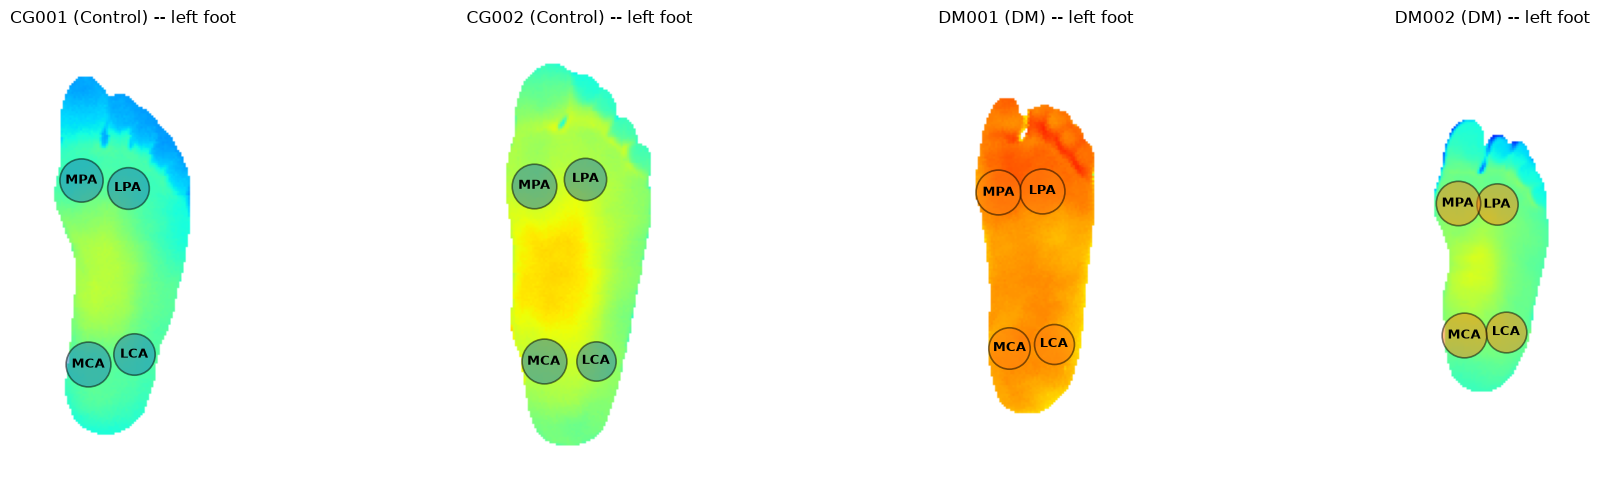

In [7]:
print("=== SECTION 6: Per-Subject Visual Example ===")

split_manifest_df = pd.read_csv(DATA_DIR / "split_manifest.csv")

control_subjects = sorted(manifest_df.loc[manifest_df["group"] == "Control", "subject_id"].unique())[:2]
dm_subjects = sorted(manifest_df.loc[manifest_df["group"] == "DM", "subject_id"].unique())[:2]
example_subjects = [(s, "Control") for s in control_subjects] + [(s, "DM") for s in dm_subjects]
print(f"Selected subjects (first alphabetically per group): {example_subjects}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (subject_id, grp) in zip(axes, example_subjects):
    row_idx = manifest_df.index[
        (manifest_df["subject_id"] == subject_id) & (manifest_df["foot_side"] == "L")
    ][0]
    importance_scores = all_importance[row_idx]  # (4,) in NODE_ORDER

    split_row = split_manifest_df[
        (split_manifest_df["subject_id"] == subject_id) & (split_manifest_df["foot_side"] == "L")
    ].iloc[0]
    colormap_png_path = Path(split_row["colormap_png_path"])
    mask_path = Path(split_row["mask_path"])

    img = plt.imread(colormap_png_path)
    mask = np.load(mask_path)
    rows_nz, cols_nz = np.where(mask)
    bbox_min = np.array([rows_nz.min(), cols_nz.min()], dtype=np.float32)
    bbox_max = np.array([rows_nz.max(), cols_nz.max()], dtype=np.float32)

    npz = np.load(manifest_df.loc[row_idx, "npz_path"])
    raw_node_features = npz["node_features"]  # NOT z-score normalized -- centroid cols are already [0,1]

    ax.imshow(img)
    for i, region in enumerate(NODE_ORDER):
        centroid_norm = raw_node_features[i, 4:6]  # [row_norm, col_norm]
        centroid_canvas = bbox_min + centroid_norm * (bbox_max - bbox_min)
        size = 200 + 3000 * float(importance_scores[i])
        color = "#ff7f0e" if grp == "DM" else "#1f77b4"
        ax.scatter(centroid_canvas[1], centroid_canvas[0], s=size, alpha=0.5,
                   color=color, edgecolors="black", linewidths=1.2)
        ax.annotate(region, (centroid_canvas[1], centroid_canvas[0]), color="black",
                    fontsize=9, ha="center", va="center", fontweight="bold")
    ax.set_title(f"{subject_id} ({grp}) -- left foot")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Section 7 — Save Results

Save the full 334-row per-region importance table and the group-comparison statistics.

In [8]:
print("=== SECTION 7: Save Results ===")

region_out_path = RESULTS_DIR / "attention_region_importance.csv"
region_df.to_csv(region_out_path, index=False)
print(f"Saved {region_out_path} -- shape {region_df.shape} (expected (334, 7))")

group_comparison = {
    row["region"]: {
        "control_mean": row["control_mean"], "control_std": row["control_std"],
        "dm_mean": row["dm_mean"], "dm_std": row["dm_std"],
        "mannwhitney_u": row["mannwhitney_u"], "p_value": row["p_value"],
    }
    for row in comparison_df.to_dict("records")
}
comparison_out_path = RESULTS_DIR / "attention_group_comparison.json"
with open(comparison_out_path, "w") as f:
    json.dump(group_comparison, f, indent=2)
print(f"Saved {comparison_out_path}")

=== SECTION 7: Save Results ===
Saved results\attention_region_importance.csv -- shape (334, 7) (expected (334, 7))
Saved results\attention_group_comparison.json


## Section 8 — Final Summary

In [9]:
print("=== SECTION 8: Final Summary ===")

strongest_region_row = comparison_df.loc[comparison_df["p_value"].idxmin()]
print(f"Region with strongest Control-vs-DM attention separation: {strongest_region_row['region']}")
print(f"  p-value: {strongest_region_row['p_value']:.4f}")
print(f"  Control mean: {strongest_region_row['control_mean']:.4f} +/- {strongest_region_row['control_std']:.4f}")
print(f"  DM mean: {strongest_region_row['dm_mean']:.4f} +/- {strongest_region_row['dm_std']:.4f}")

print()
print("Comparison to k-GCNDFU: k-GCNDFU identified MCA (Medial Calcaneal Artery) as the key")
print("region via GNNExplainer on a related dataset. See the Section 5 markdown cell, filled in")
print("from the table above, for this run's plain comparison against that finding.")

print()
print(f"Extraction method actually used: {EXTRACTION_METHOD}")

print()
issues = []
if max_dev > 1e-3:
    issues.append(f"Attention row-sum deviation from 1.0 exceeded tolerance: {max_dev:.2e}")
if bool(np.isnan(all_importance).any()):
    issues.append("NaNs found in full-dataset importance scores.")
if issues:
    print("Issues found:")
    for issue in issues:
        print(f"  - {issue}")
else:
    print("0 issues found.")

print()
print(f"Saved: {RESULTS_DIR / 'attention_region_importance.csv'}")
print(f"Saved: {RESULTS_DIR / 'attention_group_comparison.json'}")

=== SECTION 8: Final Summary ===
Region with strongest Control-vs-DM attention separation: MCA
  p-value: 0.0000
  Control mean: 0.2651 +/- 0.0422
  DM mean: 0.2330 +/- 0.0458

Comparison to k-GCNDFU: k-GCNDFU identified MCA (Medial Calcaneal Artery) as the key
region via GNNExplainer on a related dataset. See the Section 5 markdown cell, filled in
from the table above, for this run's plain comparison against that finding.

Extraction method actually used: manual_recomputation

0 issues found.

Saved: results\attention_region_importance.csv
Saved: results\attention_group_comparison.json
